# Recorded M13 benchmark and browser-parity boundary

**Question:** What do the recorded M08/M13 scores show across STEAD stress strata, and which inference paths remain unverified?
**Level 3 — Research critique**  
**Prerequisites:** Levels 1–2 and inverse-problem fundamentals; 35 min.

## Objectives

Compare native M08/M13 phase scores across real STEAD stress strata, keeping benchmark quality separate from unverified browser parity.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Data

The held-out benchmark stores native M08/M13 results; the lesson separately runs the product classical STA/LTA method on one selected trace. The browser ONNX asset is not executed here.

**Source and rights:** STEAD by Mousavi et al. ([official repository](https://github.com/smousavi05/STEAD), [paper DOI](https://doi.org/10.1109/ACCESS.2019.2947848)) is CC BY 4.0 ([license](https://github.com/smousavi05/STEAD/blob/master/LICENSE)). The selected browser asset is a modified derivative: source ZNE reordered to ENZ, mean-removed, peak-normalized unrestituted counts; analyst picks are references, not geological truth. No instrument response or physical motion units are represented.

## Method

PhaseNet maps three-component waveforms to samplewise phase probabilities; peak and threshold rules determine picks. Cite the primary paper/software, but use only this product’s held-out evidence: 6,000 real STEAD traces, 5,926 valid, 74 rejected, analyst references at ±0.5 s. Browser assets are 24 real 100 Hz, 60 s traces, normalized float32 counts. Manifest explicitly says browser parity is false and probabilities are not calibrated. Plot native M08/M13 P/S F1 and noise false-pick rates, with parity called out as a separate gate. Native accuracy cannot stand in for in-browser execution. Release evidence must compare probabilities and picks on identical held-out traces, preserve negative cases and disclose annotation uncertainty and domain shift.

PhaseNet maps three-component waveforms to samplewise phase probabilities; peak and threshold rules produce picks. Held-out F1 at ±0.5 s and valid-noise false-pick fraction answer different questions. The browser manifest has only 24 selected traces and explicitly marks parity false and probabilities uncalibrated, so native scores cannot establish browser inference.

## Comparison

The research context is not a leaderboard: separate published formulation from the product implementation and its committed evidence. A claim of advance would require independent held-out domains, calibrated uncertainty and replication.

### Learned phase picking and the evidence boundary

PhaseNet is a fully convolutional temporal model that maps three-component waveform windows to sample-wise P, S and noise probabilities. A peak detector and phase-specific thresholds convert those probabilities into arrival candidates. Its learned representation differs from STA/LTA, which forms short-to-long energy ratios and reports threshold crossings without a phase classifier. Both methods depend on correct component orientation, sample interval, waveform normalization and pick-reference convention. A missing component or changed acquisition response is a domain shift, not merely a plotting difference.

This repository’s held-out benchmark uses event and station grouping to reduce leakage from correlated traces. It reports performance at a stated time tolerance and retains QC rejects in the evaluation denominator as unpicked cases where specified. F1 combines precision and recall; a high F1 alone can conceal false triggers in valid noise windows, so the false-pick fraction is reported separately. Stratifying by component loss, noise and temporal shift tests specific stress conditions but does not cover every instrument, tectonic region or annotation practice.

The browser asset manifest contains only 24 selected traces and marks browser parity false and probabilities uncalibrated. Native runtime benchmark results do not prove that a browser implementation uses identical weights, normalization, channel mapping, tensor layout, peak logic and precision. Parity requires comparing raw per-sample outputs and final picks on the same fixed traces with documented tolerances. Until that gate passes, the browser view is an inspection aid and not a validated PhaseNet inference service.

The trace-level STA/LTA calls in this lesson are executable baseline analysis on real STEAD-derived samples. Their early P candidate illustrates why a single example cannot summarize population quality. The repository’s M08/M13 evidence uses held-out traces and retains misses and valid-noise false picks. Analyst labels are reference picks, not geological truth; timing tolerance and annotation uncertainty bound the interpretation. No new learned model is trained here, and no unverified probability calibration is implied.

## Results

**Answer:** The real STEAD selection has 6,000 traces (5,926 valid, 74 QC-rejected). Browser parity and probability calibration are false; the inspected trace gives P=1.19 s and S=7.02 s against references 7.00 s and 12.77 s.

## Summary

Native scores describe the recorded STEAD benchmark only. Browser parity remains unverified until probabilities and picks are compared on identical traces; analyst arrivals carry timing uncertainty and are not geological truth.

## References

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)


**Product-scope blocker:** This notebook plots saved native benchmark metrics and runs the product M08 classical picker on one real trace, but does not execute the product M13 ONNX inference on the same held-out traces. Browser parity remains explicitly false. Required work is pinned native/browser M13 inference on identical traces with probability and pick parity measurements; saved scores are not a substitute.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
# Inspect real held-out benchmark plus browser asset gates.
import json
from pathlib import Path

b = json.loads((root / "data/derived/phase/stead-heldout-benchmark.json").read_text(encoding="utf-8"))
m = json.loads((root / "data/derived/phase/browser-assets/stead/manifest.json").read_text(encoding="utf-8"))
print("selected/valid/rejected", b["selected"], b["valid"], b["qc_rejected"], "reference", b["reference"])


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
selected/valid/rejected 6000 5926 74 reference STEAD manual P/S picks, not geological truth


### The benchmark manifest identifies the selected browser traces, three-component input shape, sampling rate, and calibration metadata. Report parity and probability calibration as separate fields: a native runtime score cannot demonstrate that the browser uses the same weights, preprocessing, or output conventions.

El manifiesto identifica las trazas del navegador, la forma de entrada de tres componentes, frecuencia de muestreo y calibración. Informe paridad y calibración de probabilidades por separado: una puntuación del runtime nativo no demuestra que el navegador use los mismos pesos, preprocesamiento o convención de salida.

In [2]:
# Keep native scores and browser parity separate because they validate different execution paths.
print(
    "browser traces",
    m["selection"]["selected"],
    "shape",
    m["input"]["shape"],
    "Hz",
    m["input"]["sample_rate_hz"],
    "parity",
    m["browser_parity_verified"],
    "calibrated",
    m["model"]["probabilities_calibrated"],
)


browser traces 24 shape [1, 3, 6000] Hz 100 parity False calibrated False


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

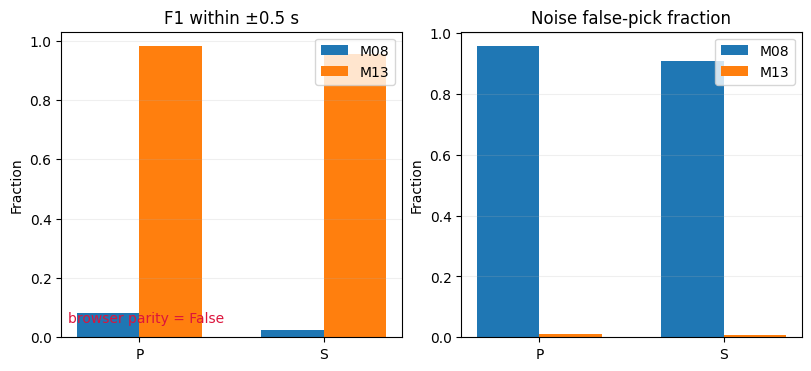

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Compare native-runtime held-out F1 and noise false-pick rate; parity stays an independent gate.
import matplotlib.pyplot as plt

e = b["metrics"]["nominal"]
phase = ["P", "S"]
x = np.arange(2)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6), constrained_layout=True)
for a, key, title in zip(
    ax, ["f1_at_0p5s", "valid_noise_false_pick_rate"], ["F1 within ±0.5 s", "Noise false-pick fraction"]
):
    for i, name in enumerate(("M08", "M13")):
        a.bar(x + i * 0.34, [e[name][p][key] for p in phase], 0.34, label=name)
    a.set(xticks=x + 0.17, xticklabels=phase, ylabel="Fraction", title=title)
    a.legend()
    a.grid(axis="y", alpha=0.2)
ax[0].text(
    0.02,
    0.05,
    "browser parity = " + str(m["browser_parity_verified"]),
    transform=ax[0].transAxes,
    color="crimson",
)
plt.show()


### The saved native benchmark contains matched M08/M13 results by stress stratum. Browser parity is a separate release property; keep it false unless the browser implementation has been run on the same traces and compared numerically. This cell preserves the distinction between model quality evidence and deployment-equivalence evidence.

El benchmark nativo conserva resultados pareados M08/M13 por estrato de estrés. La paridad del navegador es una propiedad de publicación aparte y debe seguir en falso hasta ejecutar la implementación del navegador sobre las mismas trazas y compararla numéricamente. Esta celda separa evidencia de calidad del modelo y equivalencia de despliegue.

In [4]:
# Keep native scores and browser parity separate because they validate different execution paths.
print("Native score does not establish browser parity.")


Native score does not establish browser parity.


### Experiment: matched held-out stress strata and the parity boundary

The benchmark records M08 and M13 on the same source traces across nominal, component-dropout, higher-noise and time-shift strata. Replot the per-phase F1 and valid-noise false-pick fraction for every stratum. These are native benchmark results against STEAD analyst picks (not geological truth); failed QC cases count as unpicked. The ONNX asset’s manifest explicitly says browser parity is **not verified**, so native scores do not establish that the online/browser model runs identically. Also inspect the real browser tensor contract (100 Hz, 3 components, 6000 samples, normalized counts) and explain why input normalization, threshold and channel order must match before parity can be claimed.

In [5]:
# Prepare matched stress-stratum coordinates for the native-runtime comparison.
strata = list(b["metrics"])
phases = ("P", "S")
x = np.arange(len(strata))
width = 0.19


### Compare native benchmark outcomes

The paired bars report M08 and M13 F1 on identical held-out strata. The second panel shows M13 valid-noise false-pick fractions, which can reveal a score increase accompanied by worse noise behavior. These are native-runtime benchmark results; browser inference parity remains unverified.

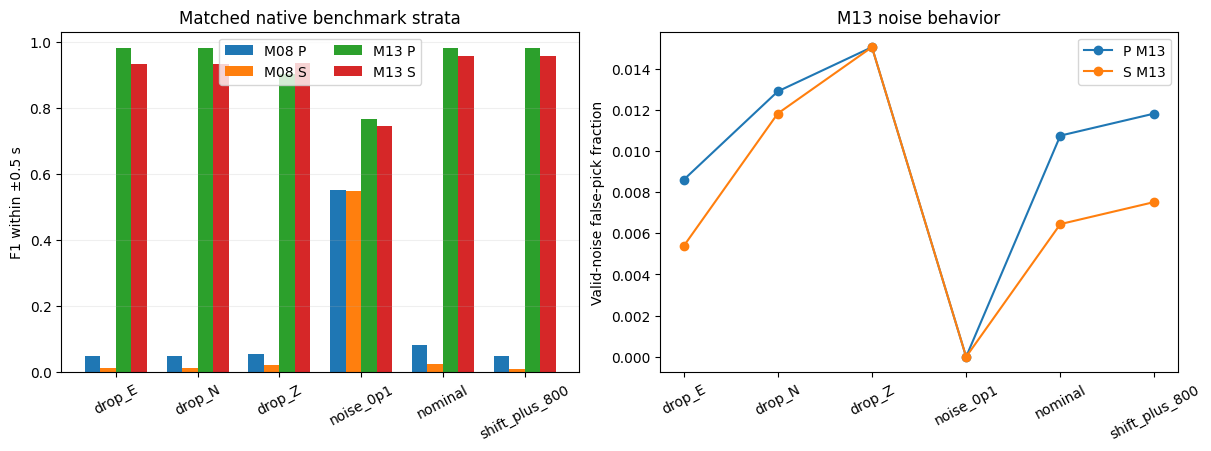

In [6]:
# Compare model and phase dimensions across the stratified validation groups.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
phases = ("P", "S")
x = np.arange(len(strata))
width = 0.19
for j, method in enumerate(("M08", "M13")):
    for k, phase in enumerate(phases):
        vals = [b["metrics"][name][method][phase]["f1_at_0p5s"] for name in strata]
        ax[0].bar(x + (j * 2 + k) * width, vals, width, label=f"{method} {phase}")
        if j == 1:
            nf = [b["metrics"][name][method][phase]["valid_noise_false_pick_rate"] for name in strata]
            ax[1].plot(x, nf, marker="o", label=f"{phase} M13")
ax[0].set(
    xticks=x + 1.5 * width,
    xticklabels=strata,
    ylabel="F1 within ±0.5 s",
    title="Matched native benchmark strata",
)
ax[0].tick_params(axis="x", rotation=28)
ax[0].legend(ncol=2)
ax[0].grid(axis="y", alpha=0.2)
ax[1].set(xticks=x, xticklabels=strata, ylabel="Valid-noise false-pick fraction", title="M13 noise behavior")
ax[1].tick_params(axis="x", rotation=28)
_ = ax[1].legend()
plt.show()


### F1 within the stated time tolerance and valid-noise false-pick fraction answer different questions. The paired panels expose whether a model retains phase picks under noise stress, while the parity flag remains a distinct boundary. These scores come from the recorded held-out benchmark; they are not recomputed browser inference or a claim of clinical-quality phase labels.

F1 dentro de la tolerancia temporal y fracción de falsas detecciones con ruido válido responden preguntas distintas. Los paneles pareados muestran si el modelo conserva picks bajo estrés, mientras la bandera de paridad marca otro límite. Las puntuaciones provienen del benchmark retenido; no son inferencia recalculada en navegador ni validan etiquetas de fase para uso operativo.

In [7]:
# Keep native scores and browser parity separate because they validate different execution paths.
ax[1].grid(alpha=0.2)
plt.show()
print(
    "Browser parity verified:",
    m["browser_parity_verified"],
    "; native score must not be presented as browser inference.",
)


Browser parity verified: False ; native score must not be presented as browser inference.


### Real trace baseline

The classical STA/LTA method runs on the full three-component STEAD-derived input with the repository benchmark parameters. It returns onset candidates only; the analyst labels remain references. This single trace is not the real-data benchmark score.


In [8]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import sys

sys.path.insert(0, str(root / "data-pipeline"))
from phase_picking import classical_stalta_picks

record_trace = m["records"][0]
raw_trace = (
    np.fromfile(root / "data/derived/phase/browser-assets/stead" / record_trace["waveform_file"], dtype="<f4")
    .reshape(m["input"]["shape"])[0]
    .T
)
raw_vertical = raw_trace[:, 2]
labels = {"P": record_trace["analyst_p_s"], "S": record_trace["analyst_s_s"]}
pars = b["classical_parameters"]
trace_dt = 1.0 / float(m["input"]["sample_rate_hz"])
trace_picks = classical_stalta_picks(raw_trace, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"])
print("STA/LTA candidate picks", trace_picks)


STA/LTA candidate picks {'P': 1.19, 'S': 7.0200000000000005}


### Threshold change

Only the trigger ratio changes. Comparing candidate times on identical samples isolates threshold sensitivity; it does not tune the PhaseNet or M13 model and does not alter the held-out benchmark.


In [9]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
trace_picks_high = classical_stalta_picks(
    raw_trace, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"] * 1.25
)
print("higher-threshold candidates", trace_picks_high)


higher-threshold candidates {'P': 1.19, 'S': 7.0200000000000005}


### Pre-arrival control

The pre-P interval is a reference-conditioned negative control. A trigger there is a candidate false alarm for this trace, while no trigger does not prove all samples are noise.


In [10]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
prearrival = raw_trace[: max(32, int(labels["P"] / trace_dt))]
noise_candidates = classical_stalta_picks(
    prearrival, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"]
)
print("pre-arrival candidates", noise_candidates)


pre-arrival candidates {'P': 1.19, 'S': None}


### Scale control

This rerun tests amplitude-scale sensitivity on identical three-component samples. Scale normalization is distinct from instrument-response correction and does not produce calibrated phase probabilities.


In [11]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
scaled_trace = raw_trace / max(float(np.std(raw_vertical)), 1e-12)
scaled_candidates = classical_stalta_picks(
    scaled_trace, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"]
)
print("normalized-trace candidates", scaled_candidates)


normalized-trace candidates {'P': 1.19, 'S': 7.0200000000000005}


### Reference samples

The supplied analyst times are discretized at the recorded sample interval. They carry annotation uncertainty and are not independent physical truth.


In [12]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
reference_samples = {name: int(round(value / trace_dt)) for name, value in labels.items()}
print("analyst reference indices", reference_samples, "dt s", trace_dt)


analyst reference indices {'P': 700, 'S': 1277} dt s 0.01


### Score the executed candidate sets against one trace reference

The repository evaluator matches every detector variant to the identical analyst-labelled trace and applies the stated 0.5 s tolerance. P and S recall remain separate; a candidate outside tolerance is not promoted to a correct pick. One trace is a procedural check, not a benchmark estimate.


In [13]:
# Evaluate the same trace and reference for each executed STA/LTA variant.
from phase_picking import evaluate_matched_picks

trace_id = record_trace["trace_id"]
matched = evaluate_matched_picks(
    {trace_id: labels},
    {
        "default": {trace_id: trace_picks},
        "higher_threshold": {trace_id: trace_picks_high},
        "prearrival": {trace_id: noise_candidates},
        "scaled": {trace_id: scaled_candidates},
    },
    tolerance_s=0.5,
)
for method_name, phase_results in matched.items():
    print(method_name, {phase: result["correct_within_tolerance"] for phase, result in phase_results.items()})


default {'P': 0, 'S': 0}
higher_threshold {'P': 0, 'S': 0}
prearrival {'P': 0, 'S': 0}
scaled {'P': 0, 'S': 0}
